In [1]:
# ==========================================
# 1. PROJECT SETUP AND DATA LOADING
# ==========================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

# ------------------------------------------
# Project paths
# ------------------------------------------

PROJECT_ROOT = Path(
    r"D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L"
)

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw" / "images"

GRADCAM_DIR = (
    PROJECT_ROOT / "results" / "explanations" / "gradcam"
)

IG_DIR = (
    PROJECT_ROOT / "results" / "explanations" / "integrated_gradients"
)

METRICS_DIR = PROJECT_ROOT / "results" / "metrics"

STABILITY_PATH = (
    METRICS_DIR / "stability_analysis" / "stability_results.csv"
)

FAITHFULNESS_PATH = (
    METRICS_DIR / "faithfulness_analysis"
    / "faithfulness_paired_comparison.csv"
)

PREDICTIONS_PATH = (
    METRICS_DIR / "combined_test_predictions.csv"
)

OUTPUT_DIR = (
    METRICS_DIR / "representative_case_analysis"
)

FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["plain", "satin", "twill"]

# ------------------------------------------
# Load the three existing result datasets
# ------------------------------------------

predictions_df = pd.read_csv(PREDICTIONS_PATH)

stability_df = pd.read_csv(STABILITY_PATH)

faithfulness_df = pd.read_csv(FAITHFULNESS_PATH)

print("--- Dataset loading ---")

print("Predictions:", predictions_df.shape)
print("Stability results:", stability_df.shape)
print("Faithfulness results:", faithfulness_df.shape)

# ------------------------------------------
# Inspect columns
# ------------------------------------------

print("\n--- Prediction columns ---")
print(predictions_df.columns.tolist())

print("\n--- Stability columns ---")
print(stability_df.columns.tolist())

print("\n--- Faithfulness columns ---")
print(faithfulness_df.columns.tolist())

# ------------------------------------------
# Validate the datasets
# ------------------------------------------

assert len(predictions_df) == 130
assert predictions_df["image_filename"].nunique() == 130

assert predictions_df["actual_class"].str.lower().isin(
    CLASS_NAMES
).all()

assert PREDICTIONS_PATH.exists()
assert STABILITY_PATH.exists()
assert FAITHFULNESS_PATH.exists()

print("\nAll three result datasets loaded successfully.")

# ------------------------------------------
# Classification performance by actual class
# ------------------------------------------

predictions_df["actual_class"] = (
    predictions_df["actual_class"].str.lower()
)

predictions_df["predicted_class"] = (
    predictions_df["predicted_class"].str.lower()
)

class_performance = (
    predictions_df
    .groupby("actual_class")
    .agg(
        image_count=("image_filename", "count"),
        correct_predictions=("correct", "sum"),
        mean_confidence=("confidence", "mean")
    )
    .reindex(CLASS_NAMES)
)

class_performance["incorrect_predictions"] = (
    class_performance["image_count"]
    - class_performance["correct_predictions"]
)

class_performance["accuracy_pct"] = (
    class_performance["correct_predictions"]
    / class_performance["image_count"] * 100
)

print("\n--- Classification performance by class ---")

display(class_performance.round(3))

--- Dataset loading ---
Predictions: (130, 6)
Stability results: (520, 19)
Faithfulness results: (260, 10)

--- Prediction columns ---
['image_filename', 'actual_class', 'predicted_class', 'confidence', 'fold', 'correct']

--- Stability columns ---
['image_filename', 'condition', 'model_fold', 'original_prediction', 'perturbed_prediction', 'confidence', 'prediction_changed', 'gradcam_spearman', 'gradcam_p_value', 'ig_spearman', 'ig_p_value', 'actual_class', 'original_confidence', 'target_class', 'ig_integration_steps', 'ig_convergence_delta', 'gradcam_map_path', 'ig_map_path', 'ig_absolute_convergence_delta']

--- Faithfulness columns ---
['image_filename', 'actual_class', 'method', 'important_confidence_drop_pp', 'important_prediction_changed', 'random_mean_confidence_drop_pp', 'random_std_confidence_drop_pp', 'random_prediction_flip_rate', 'faithfulness_advantage_pp', 'important_occlusion_better']

All three result datasets loaded successfully.

--- Classification performance by clas

,image_count,correct_predictions,mean_confidence,incorrect_predictions,accuracy_pct
actual_class,,,,,
plain,50,38,0.879,12,76.000
satin,41,33,0.888,8,80.488
twill,39,31,0.836,8,79.487


Automatically select the six representative images

In [2]:
# ==========================================
# 2. SELECT SIX REPRESENTATIVE CASES
# ==========================================

selected_cases = []

for fabric_class in CLASS_NAMES:

    class_data = predictions_df[
        predictions_df["actual_class"] == fabric_class
    ].copy()

    # --------------------------------------
    # A. Select a typical correct prediction
    # --------------------------------------

    correct_cases = class_data[
        class_data["correct"] == True
    ].copy()

    median_confidence = correct_cases["confidence"].median()

    correct_cases["distance_from_median"] = (
        correct_cases["confidence"] - median_confidence
    ).abs()

    typical_correct = (
        correct_cases
        .sort_values(
            ["distance_from_median", "image_filename"]
        )
        .iloc[0]
        .copy()
    )

    typical_correct["case_type"] = "Correct"
    typical_correct["selection_reason"] = (
        "Confidence closest to the class median"
    )

    selected_cases.append(typical_correct)

    # --------------------------------------
    # B. Select the highest-confidence error
    # --------------------------------------

    incorrect_cases = class_data[
        class_data["correct"] == False
    ].copy()

    highest_confidence_error = (
        incorrect_cases
        .sort_values(
            ["confidence", "image_filename"],
            ascending=[False, True]
        )
        .iloc[0]
        .copy()
    )

    highest_confidence_error["case_type"] = "Incorrect"
    highest_confidence_error["selection_reason"] = (
        "Highest-confidence incorrect prediction"
    )

    selected_cases.append(highest_confidence_error)


# ------------------------------------------
# 3. Create the representative-case dataset
# ------------------------------------------

representative_df = pd.DataFrame(selected_cases)

representative_df = representative_df[
    [
        "image_filename",
        "actual_class",
        "predicted_class",
        "confidence",
        "fold",
        "correct",
        "case_type",
        "selection_reason"
    ]
].reset_index(drop=True)


# ------------------------------------------
# 4. Attach stability measurements
# ------------------------------------------

stability_summary = (
    stability_df
    .groupby("image_filename", as_index=False)
    .agg(
        gradcam_mean_stability=("gradcam_spearman", "mean"),
        ig_mean_stability=("ig_spearman", "mean"),
        gradcam_min_stability=("gradcam_spearman", "min"),
        ig_min_stability=("ig_spearman", "min")
    )
)

representative_df = representative_df.merge(
    stability_summary,
    on="image_filename",
    how="left",
    validate="one_to_one"
)


# ------------------------------------------
# 5. Attach faithfulness measurements
# ------------------------------------------

faithfulness_pivot = (
    faithfulness_df
    .pivot(
        index="image_filename",
        columns="method",
        values="faithfulness_advantage_pp"
    )
    .reset_index()
)

faithfulness_pivot = faithfulness_pivot.rename(
    columns={
        "Grad-CAM": "gradcam_faithfulness_advantage_pp",
        "Integrated Gradients": "ig_faithfulness_advantage_pp"
    }
)

representative_df = representative_df.merge(
    faithfulness_pivot,
    on="image_filename",
    how="left",
    validate="one_to_one"
)


# ------------------------------------------
# 6. Attach original image and map paths
# ------------------------------------------

representative_df["image_path"] = (
    representative_df["image_filename"].apply(
        lambda filename: RAW_DATA_DIR / filename
    )
)

representative_df["gradcam_path"] = representative_df.apply(
    lambda row: (
        GRADCAM_DIR
        / f"fold{int(row['fold'])}"
        / f"{Path(row['image_filename']).stem}_heatmap.npy"
    ),
    axis=1
)

representative_df["ig_path"] = representative_df.apply(
    lambda row: (
        IG_DIR
        / f"fold{int(row['fold'])}"
        / f"{Path(row['image_filename']).stem}_magnitude.npy"
    ),
    axis=1
)


# ------------------------------------------
# 7. Verify all six selected cases
# ------------------------------------------

print("--- Selected representative cases ---")

display(
    representative_df[
        [
            "image_filename",
            "actual_class",
            "predicted_class",
            "confidence",
            "fold",
            "case_type",
            "gradcam_mean_stability",
            "ig_mean_stability",
            "gradcam_faithfulness_advantage_pp",
            "ig_faithfulness_advantage_pp"
        ]
    ].round(4)
)

print("\n--- File availability ---")

for column in ["image_path", "gradcam_path", "ig_path"]:

    available = representative_df[column].apply(
        lambda path: Path(path).exists()
    )

    print(
        f"{column}: {available.sum()}/{len(representative_df)} found"
    )


# ------------------------------------------
# 8. Final checks
# ------------------------------------------

assert len(representative_df) == 6
assert representative_df["image_filename"].nunique() == 6
assert representative_df["image_path"].apply(Path.exists).all()
assert representative_df["gradcam_path"].apply(Path.exists).all()
assert representative_df["ig_path"].apply(Path.exists).all()

assert (
    representative_df
    .groupby("actual_class")["case_type"]
    .value_counts()
    .unstack(fill_value=0)
    .eq(1)
    .all()
    .all()
)

print("\nSUCCESS: Six representative cases selected and verified.")

--- Selected representative cases ---


,image_filename,actual_class,predicted_class,confidence,fold,case_type,gradcam_mean_stability,ig_mean_stability,gradcam_faithfulness_advantage_pp,ig_faithfulness_advantage_pp
0,W023.jpg,plain,plain,0.9452,5,Correct,0.9517,0.6352,-1.7199,-5.7075
1,W056.jpg,plain,satin,0.9709,1,Incorrect,0.8505,0.5385,-6.6728,-22.5413
2,W068.jpg,satin,satin,0.9947,1,Correct,0.9461,0.5488,1.7096,-0.3999
3,W090.jpg,satin,plain,0.9796,3,Incorrect,0.8974,0.6835,-6.1124,-2.2692
4,W037.jpg,twill,twill,0.9456,3,Correct,0.8596,0.7386,5.7208,0.7280
5,W123.jpg,twill,satin,0.9304,2,Incorrect,0.8191,0.6987,-20.0693,-15.4829



--- File availability ---
image_path: 6/6 found
gradcam_path: 6/6 found
ig_path: 6/6 found

SUCCESS: Six representative cases selected and verified.


Visualize all six representative cases

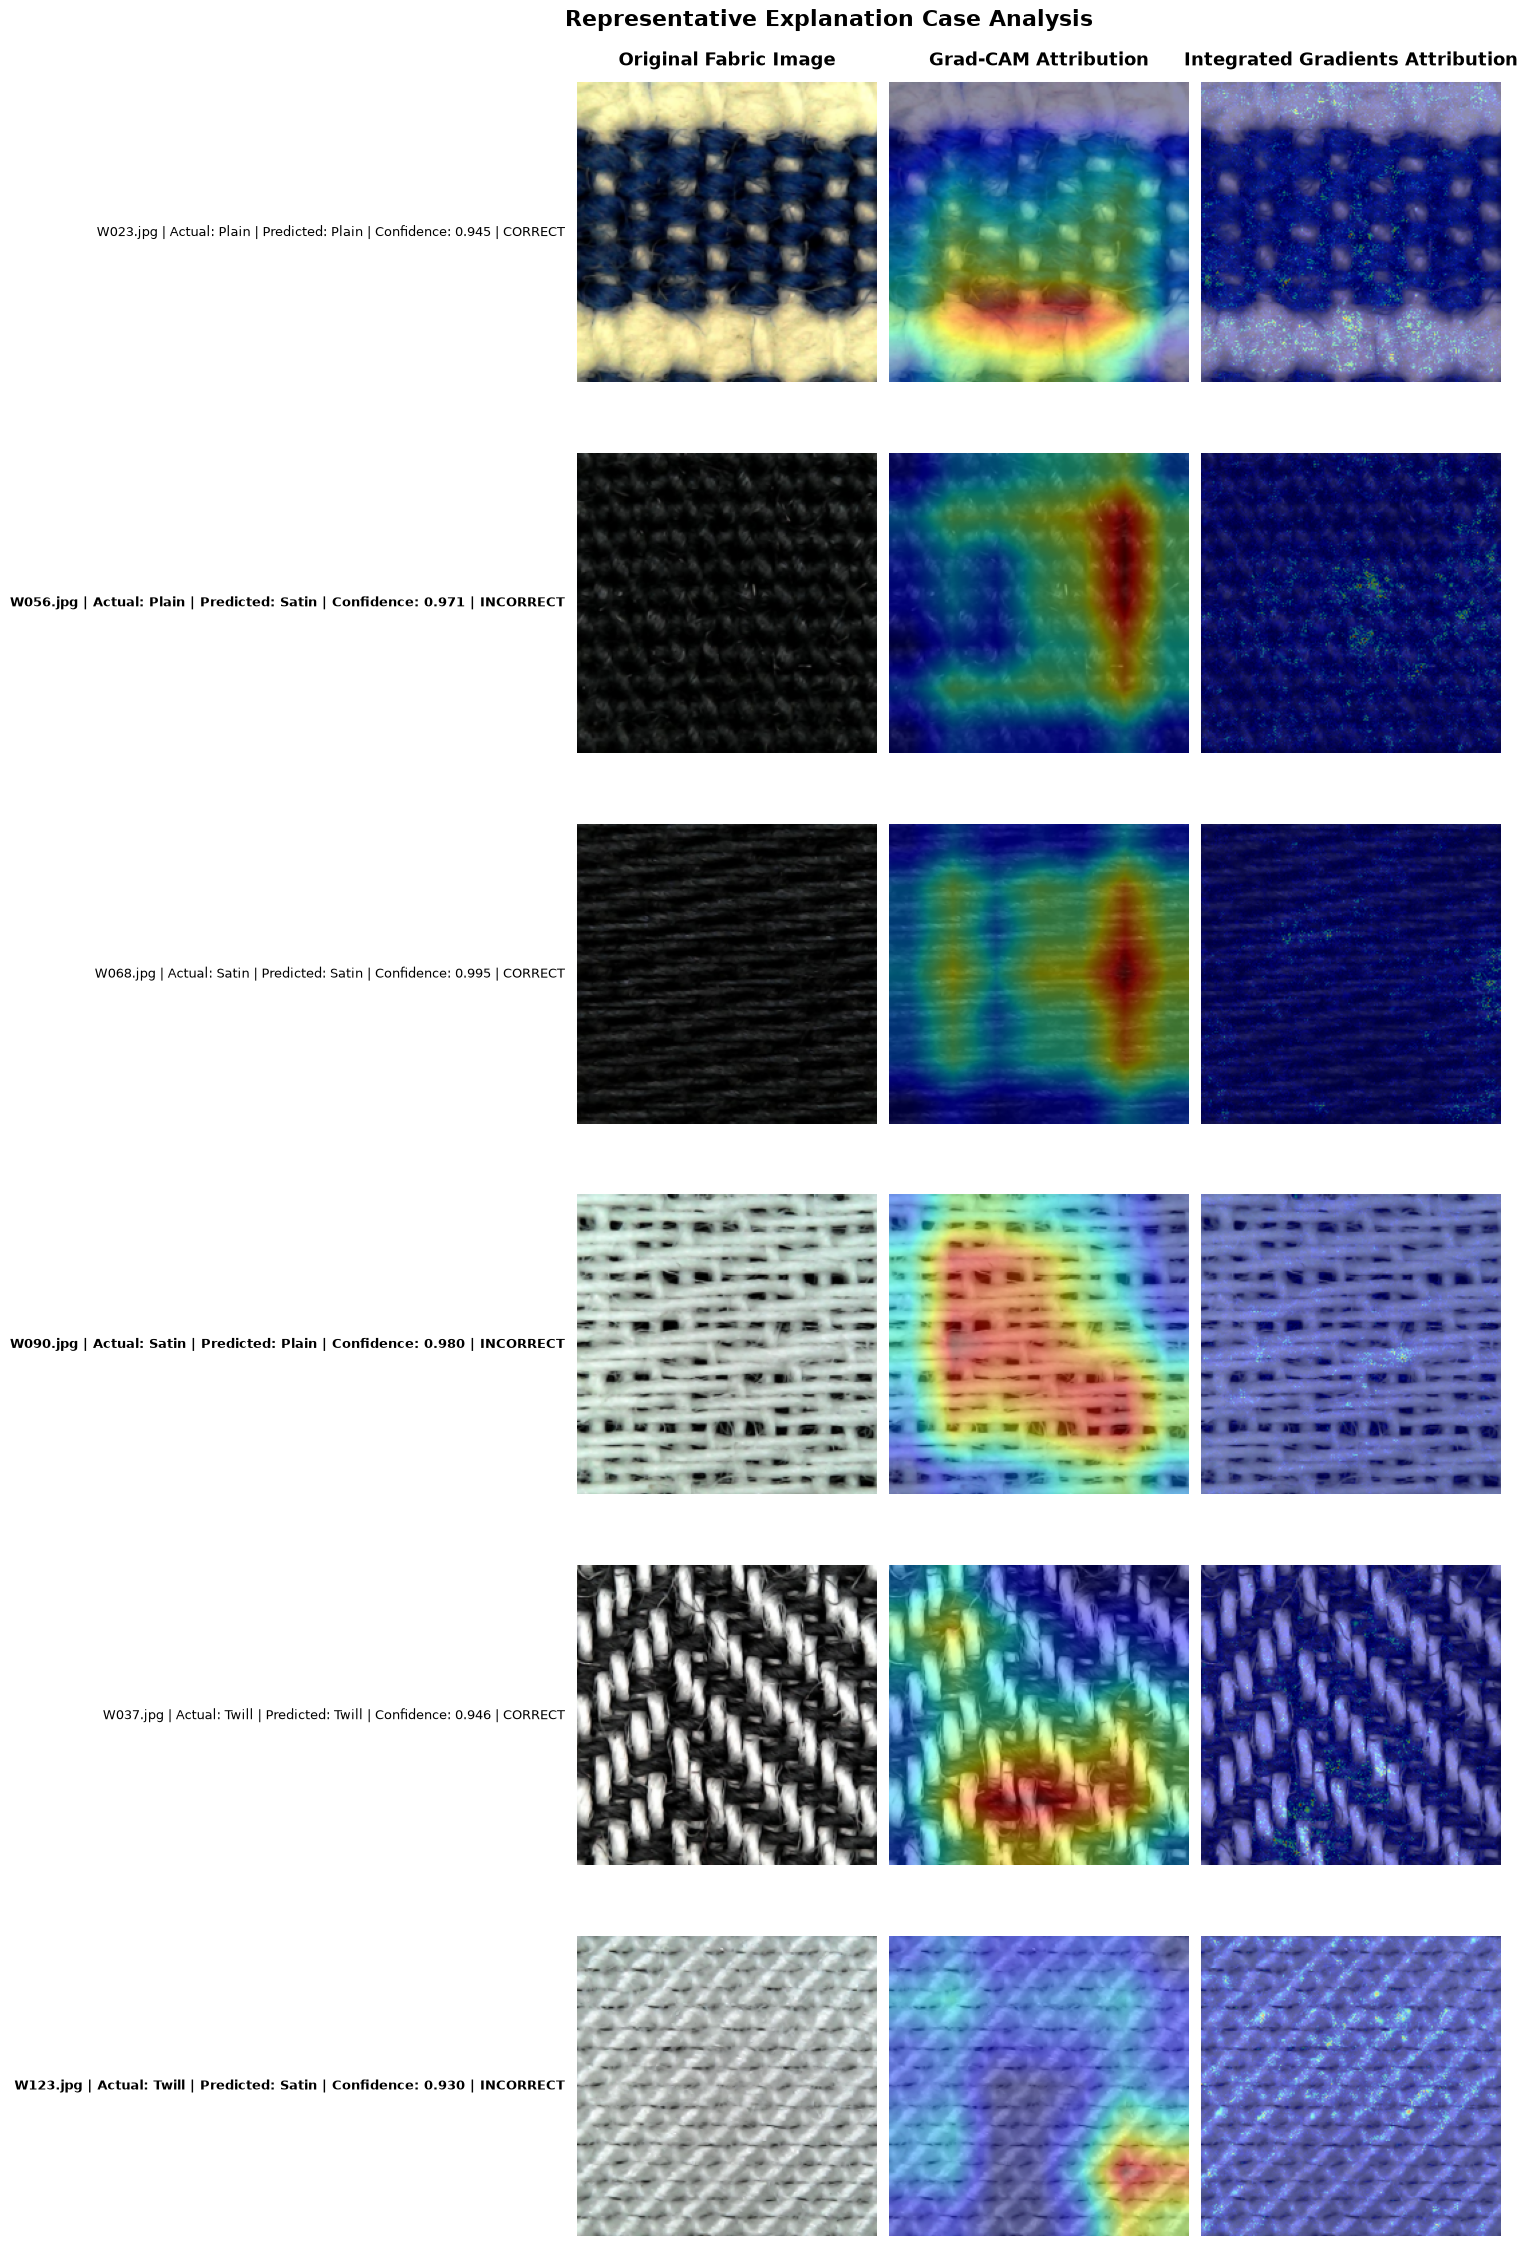


Representative case visualization saved:
D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\figures\representative_explanation_cases.png


In [3]:
# ==========================================
# 3. VISUALIZE SIX REPRESENTATIVE CASES
# ==========================================

from torchvision import transforms
import matplotlib.pyplot as plt
import numpy as np

# Same spatial preprocessing as the trained model
display_transform = transforms.Compose([
    transforms.CenterCrop(480),
    transforms.Resize((224, 224))
])

def normalize_attribution(attribution_map):
    """Normalize an attribution map to [0, 1] for visualization."""

    attribution_map = np.asarray(
        attribution_map,
        dtype=np.float32
    )

    minimum = np.min(attribution_map)
    maximum = np.max(attribution_map)

    if maximum - minimum < 1e-12:
        return np.zeros_like(attribution_map)

    return (attribution_map - minimum) / (maximum - minimum)


# Create six-row, three-column figure
fig, axes = plt.subplots(
    nrows=6,
    ncols=3,
    figsize=(14, 23)
)

column_titles = [
    "Original Fabric Image",
    "Grad-CAM Attribution",
    "Integrated Gradients Attribution"
]

for col, title in enumerate(column_titles):
    axes[0, col].set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=12
    )


for row_index, (_, case) in enumerate(
    representative_df.iterrows()
):

    # --------------------------------------
    # 1. Load original fabric image
    # --------------------------------------

    with Image.open(case["image_path"]) as image:
        image = image.convert("RGB")
        processed_image = display_transform(image)

    image_array = np.asarray(processed_image)

    # --------------------------------------
    # 2. Load attribution maps
    # --------------------------------------

    gradcam_map = np.load(case["gradcam_path"])
    ig_map = np.load(case["ig_path"])

    gradcam_display = normalize_attribution(
        gradcam_map
    )

    ig_display = normalize_attribution(
        ig_map
    )

    # --------------------------------------
    # 3. Display original image
    # --------------------------------------

    axes[row_index, 0].imshow(image_array)

    # --------------------------------------
    # 4. Display Grad-CAM overlay
    # --------------------------------------

    axes[row_index, 1].imshow(image_array)

    axes[row_index, 1].imshow(
        gradcam_display,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1,
        interpolation="bilinear"
    )

    # --------------------------------------
    # 5. Display Integrated Gradients overlay
    # --------------------------------------

    axes[row_index, 2].imshow(image_array)

    axes[row_index, 2].imshow(
        ig_display,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1,
        interpolation="bilinear"
    )

    # --------------------------------------
    # 6. Add case information
    # --------------------------------------

    case_status = (
        "CORRECT" if case["correct"] else "INCORRECT"
    )

    case_label = (
        f"{case['image_filename']} | "
        f"Actual: {case['actual_class'].capitalize()} | "
        f"Predicted: {case['predicted_class'].capitalize()} | "
        f"Confidence: {case['confidence']:.3f} | "
        f"{case_status}"
    )

    axes[row_index, 0].text(
        -0.04,
        0.5,
        case_label,
        transform=axes[row_index, 0].transAxes,
        ha="right",
        va="center",
        fontsize=9,
        fontweight="bold" if not case["correct"] else "normal"
    )

    # Remove axes for cleaner figures
    for col in range(3):
        axes[row_index, col].set_xticks([])
        axes[row_index, col].set_yticks([])

        for spine in axes[row_index, col].spines.values():
            spine.set_visible(False)


# ------------------------------------------
# 7. Save final visualization
# ------------------------------------------

plt.suptitle(
    "Representative Explanation Case Analysis",
    fontsize=16,
    fontweight="bold",
    y=0.995
)

plt.subplots_adjust(
    left=0.32,
    right=0.98,
    top=0.97,
    bottom=0.02,
    hspace=0.12,
    wspace=0.04
)

REPRESENTATIVE_FIGURE_PATH = (
    FIGURES_DIR / "representative_explanation_cases.png"
)

plt.savefig(
    REPRESENTATIVE_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nRepresentative case visualization saved:")
print(REPRESENTATIVE_FIGURE_PATH)

Prepare the qualitative review table

In [4]:
# ==========================================
# 4. QUALITATIVE CASE REVIEW TABLE
# ==========================================

qualitative_cases = pd.DataFrame([
    {
        "image_filename": "W023.jpg",
        "actual_class": "plain",
        "predicted_class": "plain",
        "case_type": "Correct",
        "gradcam_observation": "Strong activation in lower central region",
        "ig_observation": "Distributed responses around yarn intersections",
        "structure_alignment": "Requires domain review",
        "potential_suspicious_cue": "Localized lower-region activation requires inspection"
    },
    {
        "image_filename": "W056.jpg",
        "actual_class": "plain",
        "predicted_class": "satin",
        "case_type": "Incorrect",
        "gradcam_observation": "Localized vertical activation near right side",
        "ig_observation": "Diffuse responses across fabric texture",
        "structure_alignment": "Requires domain review",
        "potential_suspicious_cue": "Concentrated vertical response"
    },
    {
        "image_filename": "W068.jpg",
        "actual_class": "satin",
        "predicted_class": "satin",
        "case_type": "Correct",
        "gradcam_observation": "Strong activation in vertical regions",
        "ig_observation": "Subtle distributed responses",
        "structure_alignment": "Requires domain review",
        "potential_suspicious_cue": "Different spatial patterns between methods"
    },
    {
        "image_filename": "W090.jpg",
        "actual_class": "satin",
        "predicted_class": "plain",
        "case_type": "Incorrect",
        "gradcam_observation": "Concentrated central activation",
        "ig_observation": "Distributed responses across weave texture",
        "structure_alignment": "Requires domain review",
        "potential_suspicious_cue": "Localized central response"
    },
    {
        "image_filename": "W037.jpg",
        "actual_class": "twill",
        "predicted_class": "twill",
        "case_type": "Correct",
        "gradcam_observation": "Strong central and lower-region activation",
        "ig_observation": "Responses along repeated diagonal texture",
        "structure_alignment": "Potential alignment with visible diagonal texture",
        "potential_suspicious_cue": "Grad-CAM concentration requires inspection"
    },
    {
        "image_filename": "W123.jpg",
        "actual_class": "twill",
        "predicted_class": "satin",
        "case_type": "Incorrect",
        "gradcam_observation": "Strong bottom-right localized activation",
        "ig_observation": "Distributed responses along diagonal texture",
        "structure_alignment": "Requires domain review",
        "potential_suspicious_cue": "Localized Grad-CAM response despite incorrect prediction"
    }
])

display(qualitative_cases)

# Save the qualitative review data
QUALITATIVE_PATH = (
    OUTPUT_DIR / "qualitative_case_review.csv"
)

qualitative_cases.to_csv(
    QUALITATIVE_PATH,
    index=False
)

print("\nQualitative case review saved:")
print(QUALITATIVE_PATH)

,image_filename,actual_class,predicted_class,case_type,gradcam_observation,ig_observation,structure_alignment,potential_suspicious_cue
0,W023.jpg,plain,plain,Correct,Strong activation in lower central region,Distributed responses around yarn intersections,Requires domain review,Localized lower-region activation requires ins...
1,W056.jpg,plain,satin,Incorrect,Localized vertical activation near right side,Diffuse responses across fabric texture,Requires domain review,Concentrated vertical response
2,W068.jpg,satin,satin,Correct,Strong activation in vertical regions,Subtle distributed responses,Requires domain review,Different spatial patterns between methods
3,W090.jpg,satin,plain,Incorrect,Concentrated central activation,Distributed responses across weave texture,Requires domain review,Localized central response
4,W037.jpg,twill,twill,Correct,Strong central and lower-region activation,Responses along repeated diagonal texture,Potential alignment with visible diagonal texture,Grad-CAM concentration requires inspection
5,W123.jpg,twill,satin,Incorrect,Strong bottom-right localized activation,Distributed responses along diagonal texture,Requires domain review,Localized Grad-CAM response despite incorrect ...



Qualitative case review saved:
D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\representative_case_analysis\qualitative_case_review.csv


Qualitative Analysis and Discussion

Representative Case Selection

Six representative fabric images were selected from the 130-image dataset, including one correctly classified and one incorrectly classified example from each fabric class. Correct cases were selected based on confidence closest to the class median, while incorrect cases were selected based on the highest prediction confidence.

Correct Predictions

W023 (Plain) and W068 (Satin) demonstrate correct predictions with confidence values of 94.52% and 99.47%, respectively. Their Grad-CAM and Integrated Gradients maps show different spatial attribution patterns.

W037 (Twill), correctly classified with 94.56% confidence, provides an interesting example because the Integrated Gradients attribution appears to respond to portions of the visible diagonal textile texture.

These examples demonstrate that correct classification does not necessarily mean that both explanation methods identify identical image regions.

Incorrect Predictions

Three high-confidence misclassifications were examined:

W056: Plain was classified as Satin with 97.09% confidence.

W090: Satin was classified as Plain with 97.96% confidence.

W123: Twill was classified as Satin with 93.04% confidence.

These cases demonstrate that high prediction confidence does not guarantee correct fabric structure classification.

The corresponding attribution maps also show differences between Grad-CAM and Integrated Gradients. In particular, localized Grad-CAM activations were observed in W056 and W123, while Integrated Gradients generally showed more distributed attribution patterns in the visual comparisons.

These patterns identify potentially interesting cases for further investigation, but do not independently establish that the classifier relied on irrelevant or non-structural features.

Overall Interpretation

The representative-case analysis complements the quantitative stability and faithfulness experiments. It demonstrates differences in spatial attribution patterns between the two XAI methods and highlights examples where incorrect classifications occur despite high confidence.

However, the visual analysis is exploratory. Confirming whether the highlighted regions correspond to meaningful woven structures or non-structural visual cues would require further textile-domain assessment.

The findings therefore support a cautious interpretation of explainability results: visually plausible attribution maps should not automatically be considered reliable evidence of the model's decision-making process.